In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [78]:
k_df = pd.read_csv('../k_saves/k_results_create_mix_noamp_vHSR.tsv', sep ='\t')

In [79]:
k_df_filtered = k_df[k_df["HSR_percent"] != 0]

# Average replicates for each (total_cells, k)
avg_df = (
    k_df_filtered
    .groupby(["total_cells", "k"], as_index=False)
    ["pred_ecDNA_percent"]
    .mean()
)

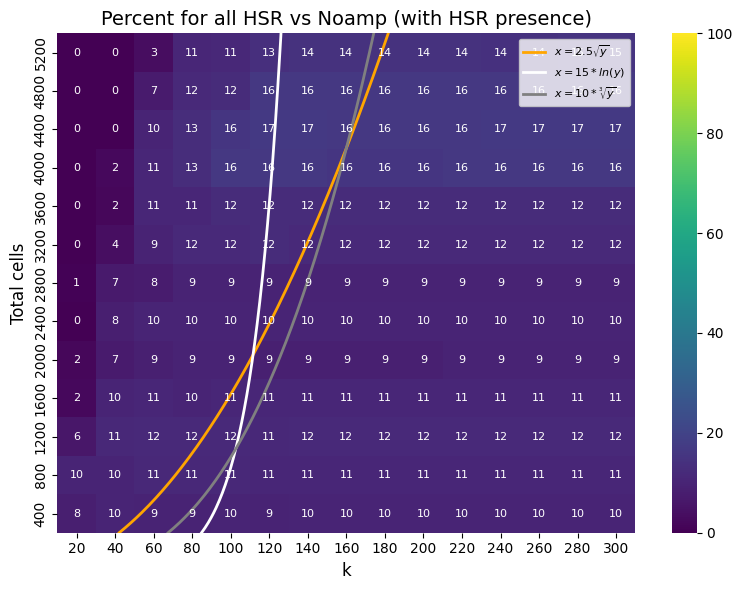

In [80]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def add_heatmap_curve(ax, heatmap, x_func, label, color="red", linewidth=2, linestyle="-"):
    """
    Add a curve x=f(y) on top of a seaborn heatmap.

    Parameters:
        ax       : matplotlib axis
        heatmap  : heatmap dataframe (index = y axis, columns = x axis)
        x_func   : function that takes y and returns x
        label    : legend label
        color    : line color
    """
    
    y = np.linspace(heatmap.index.min(), heatmap.index.max(), 200)
    x = x_func(y)

    # Convert data coordinates -> heatmap pixel coordinates
    x_plot = (
        (x - heatmap.columns.min())
        / (heatmap.columns.max() - heatmap.columns.min())
        * len(heatmap.columns)
    )

    # Account for reversed y-axis from sort_index(ascending=False)
    y_plot = (
        (heatmap.index.max() - y)
        / (heatmap.index.max() - heatmap.index.min())
        * len(heatmap.index)
    )

    ax.plot(
        x_plot,
        y_plot,
        color=color,
        linewidth=linewidth,
        linestyle=linestyle,
        label=label
    )
    
# X = total_cells (col 2)
# Y = ecDNA_percent (col 3)
# Value = pred_ecDNA_percent (col 5)

heatmap = (
    avg_df
    .pivot(index="total_cells",
           columns="k",
           values="pred_ecDNA_percent")
    .sort_index(ascending = False)
)

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    heatmap,
    ax=ax,
    annot=True,
    fmt=".0f",
    cmap="viridis",
    annot_kws={"fontsize": 8},
    vmin=0,
    vmax=100
)

add_heatmap_curve(
    ax,
    heatmap,
    lambda y: 2.5*np.sqrt(y),
    r"$x=2.5\sqrt{y}$",
    color="orange"
)

# add_heatmap_curve(
#     ax,
#     heatmap,
#     lambda y: 1.5*np.sqrt(y),
#     r"$x=1.5\sqrt{y}$",
#     color="cornflowerblue",
# )

add_heatmap_curve(
    ax,
    heatmap,
    lambda y: 15*np.log(y),
    r"$x=15*ln(y)$",
    color="white"
)

add_heatmap_curve(
    ax,
    heatmap,
    lambda y: 10*np.cbrt(y),
    r"$x=10*\sqrt[3]{y}$",
    color="grey"
)

ax.legend(fontsize=8)

ax.set_xlabel("k", fontsize = 12)
ax.set_ylabel("Total cells", fontsize = 12)
ax.set_title("Percent for all HSR vs Noamp (with HSR presence)", fontsize = 14)

plt.tight_layout()
plt.show()